# 12 – L3 risk

Value at risk on the daily net P&L of the L2 strategy, 15 min ahead, under the adopted limits (notes/limits.md), and whether each risk model knew. Persistence is the strategy with risk worth measuring (L2: ar(1) is nearly flat); ar(1) is shown beside it. Replay on estimated vintages, not the record.

| card | |
|---|---|
| estimation window | 120 days, rolling |
| last refit | every 5 days, rolled forward daily in between |
| out-of-sample | yes: each day's VaR uses only earlier days |
| benchmark | historical simulation, expected to fail (Lyu et al. 2024) |
| exceptions | below, against expected, per model and quantile |
| structural break | 4 Mar 2026 (SatisfiedDemand: demand → activated) |

Not built: the MIDAS long-run component (a year of daily P&L can't identify one; src/nordcast/risk.py says why).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from nordcast import pnl, positions, risk

D = Path("../data/layers")
NAVY, BLUE, GREY, BAND = "#0F2A4A", "#1F5FBF", "#7D8996", "#DCE3EC"
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": BAND,
    }
)
SCEN = yaml.safe_load(Path("../notes/scenarios.yaml").read_text())
CPH = "Europe/Copenhagen"

c = pd.read_parquet(D / "calls_h15.parquet").set_index("target", drop=False)
isp, daily = {}, {}
for name in ("persistence", "forecast"):
    frame, _ = pnl.run(positions.build_positions(name, c, 15), c)
    isp[name] = frame
    d = frame.net.groupby(frame.index.tz_convert(CPH).date).sum(min_count=1)
    daily[name] = d
replay_days = pd.Index(
    sorted(set(c.target[c.replay_window].dt.tz_convert(CPH).dt.date))
)
pnl_daily = {
    k: v.reindex(replay_days).fillna(0.0) for k, v in daily.items()
}  # a flat day is 0 EUR
pd.DataFrame({k: v.describe() for k, v in pnl_daily.items()}).round(1)

,persistence,forecast
count,365.0,365.0
mean,395.0,7.9
std,918.8,105.0
min,-4401.5,-916.1
25%,-4.1,0.0
50%,207.0,0.0
75%,674.0,2.3
max,9196.6,1536.8


## Pass/fail: Kupiec (count) and Christoffersen (count and clustering), 5 % significance

In [2]:
tables, vars_ = {}, {}
for name in ("persistence", "forecast"):
    tables[name], vars_[name] = risk.compare_models(
        pnl_daily[name], qs=(0.01, 0.05), window=120
    )
matrix = tables["persistence"].assign(strategy="persistence")
pd.concat([matrix, tables["forecast"].assign(strategy="ar(1)")]).set_index(
    ["strategy", "model", "q"]
)[["days", "exceptions", "expected", "uc_p", "cc_p", "pass"]].round(3)

days  exceptions  expected   uc_p  \
strategy    model                 q                                         
persistence historical simulation 0.01   245           4      2.45  0.362   
                                  0.05   245          12     12.25  0.941   
            garch-t               0.01   245           1      2.45  0.291   
                                  0.05   245           3     12.25  0.001   
            garch-evt             0.01   245           3      2.45  0.733   
                                  0.05   245          12     12.25  0.941   
ar(1)       historical simulation 0.01   245           5      2.45  0.151   
                                  0.05   245          14     12.25  0.616   
            garch-t               0.01   245          13      2.45  0.000   
                                  0.05   245          21     12.25  0.019   
            garch-evt             0.01   245           2      2.45  0.765   
                                  0.05   245          16     12.25  0.293   

                                         cc_p   pass  
strategy    model                 q                   
persistence historical simulation 0.01  0.617   True  
                                  0.05  0.536   True  
            garch-t               0.01  0.570   True  
                                  0.05  0.005  False  
            garch-evt             0.01  0.909   True  
                                  0.05  0.536   True  
ar(1)       historical simulation 0.01  0.321   True  
                                  0.05  0.860   True  
            garch-t               0.01  0.000  False  
                                  0.05  0.040  False  
            garch-evt             0.01  0.941   True  
                                  0.05  0.356   True

**The number:** exceptions against expected at 1 %, persistence. With ~245 backtest days a 1 % VaR expects about 2.5 exceptions, so the 1 % tests have little power; the 5 % row is the one with teeth.

In [3]:
t = tables["persistence"]
t[t.q == 0.01].set_index("model")[["exceptions", "expected"]]

,exceptions,expected
model,,
historical simulation,4,2.45
garch-t,1,2.45
garch-evt,3,2.45


## Daily P&L against its 1 % and 5 % VaR (garch-evt), with historical simulation

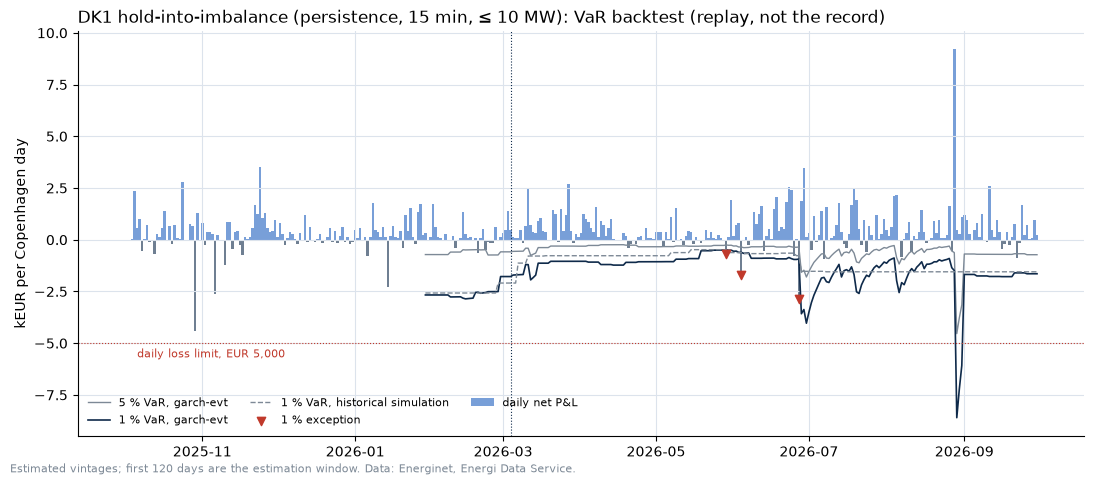

In [4]:
p = pnl_daily["persistence"]
v1, v5, hs = (
    vars_["persistence"][k]
    for k in (("garch-evt", 0.01), ("garch-evt", 0.05), ("historical simulation", 0.01))
)
x = pd.to_datetime(p.index)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(
    x,
    p / 1000,
    color=[BLUE if v >= 0 else NAVY for v in p],
    width=1.0,
    alpha=0.6,
    label="daily net P&L",
)
ax.plot(x, -v5 / 1000, color=GREY, lw=1.0, label="5 % VaR, garch-evt")
ax.plot(x, -v1 / 1000, color=NAVY, lw=1.2, label="1 % VaR, garch-evt")
ax.plot(
    x, -hs / 1000, color=GREY, lw=1.0, ls="--", label="1 % VaR, historical simulation"
)
hit = p < -v1
ax.scatter(
    x[hit.to_numpy()],
    p[hit] / 1000,
    marker="v",
    color="#c0392b",
    zorder=3,
    label="1 % exception",
)
ax.axhline(-5, color="#c0392b", lw=0.8, ls=":")
ax.text(
    x[5], -5.25, "daily loss limit, EUR 5,000", fontsize=8, color="#c0392b", va="top"
)
ax.axvline(pd.Timestamp("2026-03-04"), color=NAVY, lw=0.8, ls=":")
ax.set_ylabel("kEUR per Copenhagen day")
ax.set_title(
    "DK1 hold-into-imbalance (persistence, 15 min, ≤ 10 MW): VaR backtest (replay, not the record)",
    loc="left",
)
ax.legend(loc="lower left", frameon=False, ncol=3, fontsize=8)
fig.text(
    0.01,
    0.005,
    "Estimated vintages; first 120 days are the estimation window. Data: Energinet, Energi Data Service.",
    fontsize=8,
    color=GREY,
)
fig.tight_layout()
fig.savefig("12_risk.png", dpi=150, bbox_inches="tight")

## Stress (notes/scenarios.yaml), under the EUR 5,000 daily limit

In [5]:
rows = []
for name, label in (("persistence", "persistence"), ("forecast", "ar(1)")):
    frame, d = isp[name], daily[name]
    w = SCEN["storm_week"]
    days = [day for day in d.index if w["from"] <= str(day) <= w["to"]]
    storm = d.reindex(days)
    rows.append(
        {
            "strategy": label,
            "scenario": "storm week 20-26 Oct 2026",
            "net_eur": storm.sum(),
            "worst_day_eur": storm.min(),
            "days_covered": storm.notna().sum(),
        }
    )
    # feed outage: hold the position at the last call for hold_hours, no new information
    k = int(SCEN["feed_outage"]["hold_hours"] * 4)
    held = frame.pos_mw.fillna(0).copy()
    earned = pnl.earned_per_mw(c).reindex(held.index)
    worst = None
    for start in range(len(held) - k):  # every start, like the variant below
        block = slice(start, start + k)
        frozen = (
            held.iloc[start] * earned.iloc[block]
            - abs(held.iloc[start]) * pnl.ISP_HOURS * pnl.SLIPPAGE_EUR_MWH
        )
        loss = frozen.sum(min_count=1)
        if worst is None or (pd.notna(loss) and loss < worst[0]):
            worst = (loss, held.index[start])
    rows.append(
        {
            "strategy": label,
            "scenario": f"feed outage, {SCEN['feed_outage']['hold_hours']} h held",
            "net_eur": worst[0],
            "worst_day_eur": None,
            "days_covered": None,
            "when": worst[1].tz_convert(CPH).strftime("%d %b %Y %H:%M"),
        }
    )
    for key in ("feed_outage_under_rules", "feed_outage_under_rules_from_30_oct"):
        r = SCEN[key]
        k2, cap = max(1, int(r["hold_hours"] * 4)), r["cap_mw"]
        worst2 = None
        for start in range(len(held) - k2):
            p0 = held.iloc[start].clip(-cap, cap)
            loss = (
                p0 * earned.iloc[start : start + k2]
                - abs(p0) * pnl.ISP_HOURS * pnl.SLIPPAGE_EUR_MWH
            ).sum(min_count=1)
            if pd.notna(loss) and (worst2 is None or loss < worst2[0]):
                worst2 = (loss, held.index[start])
        rows.append(
            {
                "strategy": label,
                "scenario": f"feed outage under the rules ({cap} MW, {r['hold_hours']} h)",
                "net_eur": worst2[0],
                "when": worst2[1].tz_convert(CPH).strftime("%d %b %Y %H:%M"),
            }
        )
    rows.append(
        {
            "strategy": label,
            "scenario": "worst day",
            "net_eur": d.min(),
            "when": str(d.idxmin()),
        }
    )
pd.DataFrame(rows).set_index(["strategy", "scenario"]).round(0)

net_eur  \
strategy    scenario                                                
persistence storm week 20-26 Oct 2026                      2767.0   
            feed outage, 6 h held                        -14804.0   
            feed outage under the rules (2.5 MW, 2 h)     -4419.0   
            feed outage under the rules (2.5 MW, 0.25 h)  -2463.0   
            worst day                                     -4401.0   
ar(1)       storm week 20-26 Oct 2026                         8.0   
            feed outage, 6 h held                         -6027.0   
            feed outage under the rules (2.5 MW, 2 h)     -4225.0   
            feed outage under the rules (2.5 MW, 0.25 h)  -1003.0   
            worst day                                      -916.0   

                                                          worst_day_eur  \
strategy    scenario                                                      
persistence storm week 20-26 Oct 2026                            -173.0   
            feed outage, 6 h held                                   NaN   
            feed outage under the rules (2.5 MW, 2 h)               NaN   
            feed outage under the rules (2.5 MW, 0.25 h)            NaN   
            worst day                                               NaN   
ar(1)       storm week 20-26 Oct 2026                              -5.0   
            feed outage, 6 h held                                   NaN   
            feed outage under the rules (2.5 MW, 2 h)               NaN   
            feed outage under the rules (2.5 MW, 0.25 h)            NaN   
            worst day                                               NaN   

                                                          days_covered  \
strategy    scenario                                                     
persistence storm week 20-26 Oct 2026                              7.0   
            feed outage, 6 h held                                  NaN   
            feed outage under the rules (2.5 MW, 2 h)              NaN   
            feed outage under the rules (2.5 MW, 0.25 h)           NaN   
            worst day                                              NaN   
ar(1)       storm week 20-26 Oct 2026                              7.0   
            feed outage, 6 h held                                  NaN   
            feed outage under the rules (2.5 MW, 2 h)              NaN   
            feed outage under the rules (2.5 MW, 0.25 h)           NaN   
            worst day                                              NaN   

                                                                       when  
strategy    scenario                                                         
persistence storm week 20-26 Oct 2026                                   NaN  
            feed outage, 6 h held                         27 Jun 2026 14:30  
            feed outage under the rules (2.5 MW, 2 h)     06 Nov 2025 11:45  
            feed outage under the rules (2.5 MW, 0.25 h)  06 Nov 2025 11:45  
            worst day                                            2025-10-29  
ar(1)       storm week 20-26 Oct 2026                                   NaN  
            feed outage, 6 h held                         27 Jun 2026 15:00  
            feed outage under the rules (2.5 MW, 2 h)     27 Jun 2026 15:00  
            feed outage under the rules (2.5 MW, 0.25 h)  27 Jun 2026 15:00  
            worst day                                            2026-06-27

## What the stress says

Held at full size through a 6-hour outage, as the layer notes frame the scenario, persistence could have lost about three times the EUR 5,000 daily limit: with no prints the limit can't see the loss. The strategy's own rules don't allow that hold, though. A stale feed caps the position at 2.5 MW, and once the latest known ISP is 2 h old persistence can't build a call, so there is no position; run that way, the worst outage stays just inside the limit (the 2 h 'under the rules' row, a scenario added after the first run). The margin was thin, so from 30 Oct 2026 a feed stale by two ISPs means no position (notes/limits.md, CHANGELOG.md): an outage then risks one capped ISP (the 0.25 h row). Historical simulation, expected to fail, passes here: with ~245 backtest days the tests have little power, so that is no verdict either way.

## Where the sources disagree

The layer notes name supply-or-demand's core/risk.py; it isn't in that repo at the commit the other layers were copied from, so src/nordcast/risk.py is written fresh to spec 22's model and tests (its acceptance numbers are the tests). The notes ask for VaR on the 15-min P&L; most ISPs hold no position, so the 15-min series is mostly zeros, and the VaR is on daily P&L instead, the horizon the loss limit is set on.